<a href="https://colab.research.google.com/github/anasabrinars/Fase-1-FIAP/blob/main/Comportamentos_e_Pagamentos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
#imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
#bases

df_payments = pd.read_csv('/content/olist_order_payments_dataset.csv')

In [5]:
# pagamentos por modalidade

pagamentos = df_payments['payment_type'].value_counts().reset_index()

pagamentos.columns = ['Meio de pagamento', 'Quantidade']

pagamentos

,Meio de pagamento,Quantidade
0,credit_card,76795
1,boleto,19784
2,voucher,5775
3,debit_card,1529
4,not_defined,3


In [6]:
# % de cada pagamento

pagamentos['Percentual'] = (
    pagamentos['Quantidade'] / pagamentos['Quantidade'].sum()
) * 100

pagamentos

,Meio de pagamento,Quantidade,Percentual
0,credit_card,76795,73.922376
1,boleto,19784,19.043952
2,voucher,5775,5.558978
3,debit_card,1529,1.471806
4,not_defined,3,0.002888


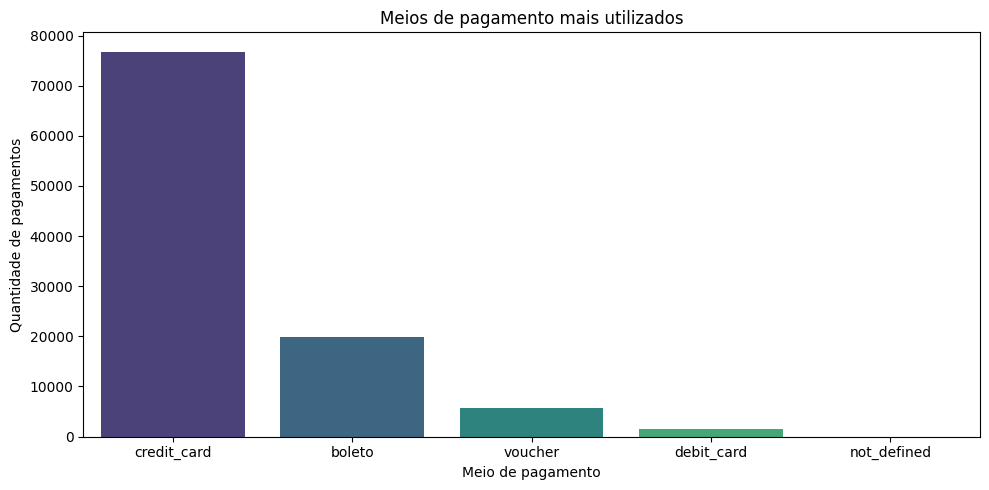

In [7]:
# visualização gráfico

plt.figure(figsize=(10,5), facecolor='none')

ax = sns.barplot(
    data=pagamentos,
    x='Meio de pagamento',
    y='Quantidade',
    hue='Meio de pagamento',
    legend=False,
    palette='viridis'
)

# Fundo transparente
ax.set_facecolor('none')
plt.gcf().patch.set_alpha(0)
ax.patch.set_alpha(0)

plt.title('Meios de pagamento mais utilizados')
plt.xlabel('Meio de pagamento')
plt.ylabel('Quantidade de pagamentos')

plt.tight_layout()

# Salvar com fundo transparente
plt.savefig('meios_pagamento.png', transparent=True, dpi=300, bbox_inches='tight')

plt.show()

In [8]:
# visualizando parcelas

parcelas = df_payments.groupby('payment_type').agg(
    quantidade_pagamentos=('payment_type', 'count'),
    media_parcelas=('payment_installments', 'mean'),
    mediana_parcelas=('payment_installments', 'median'),
    valor_medio=('payment_value', 'mean'),
    valor_total=('payment_value', 'sum')
).reset_index()

parcelas

,payment_type,quantidade_pagamentos,media_parcelas,mediana_parcelas,valor_medio,valor_total
0,boleto,19784,1.000000,1.0,145.034435,2869361.27
1,credit_card,76795,3.507155,3.0,163.319021,12542084.19
2,debit_card,1529,1.000000,1.0,142.570170,217989.79
3,not_defined,3,1.000000,1.0,0.000000,0.00
4,voucher,5775,1.000000,1.0,65.703354,379436.87


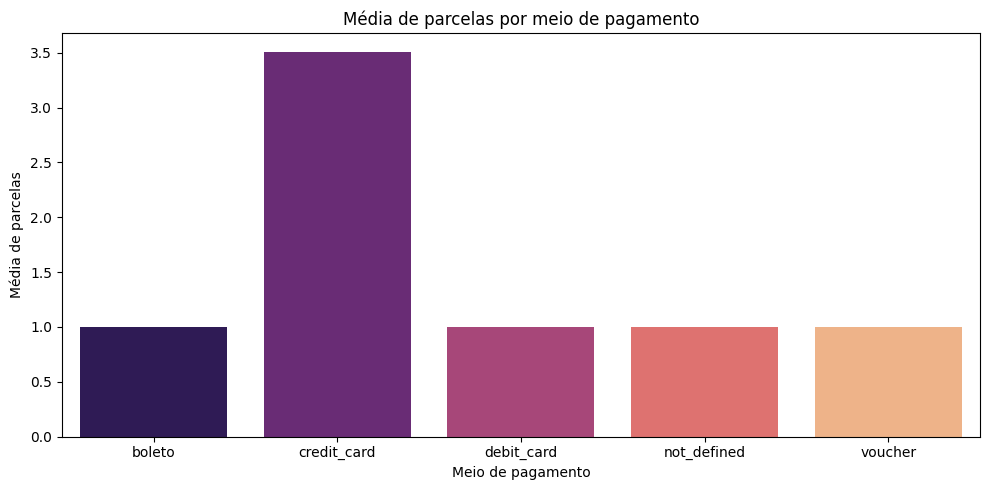

In [37]:
# visualização gráfico

plt.figure(figsize=(10,5), facecolor='none')

ax = sns.barplot(
    data=parcelas,
    x='payment_type',
    y='media_parcelas',
    hue='payment_type',
    legend=False,
    palette='magma'
)

# Fundo transparente
ax.set_facecolor('none')
plt.gcf().patch.set_alpha(0)
ax.patch.set_alpha(0)

plt.title('Média de parcelas por meio de pagamento')
plt.xlabel('Meio de pagamento')
plt.ylabel('Média de parcelas')

plt.tight_layout()

# Salvar com fundo transparente
plt.savefig('media_parcelas.png', transparent=True, dpi=300, bbox_inches='tight')

plt.show()

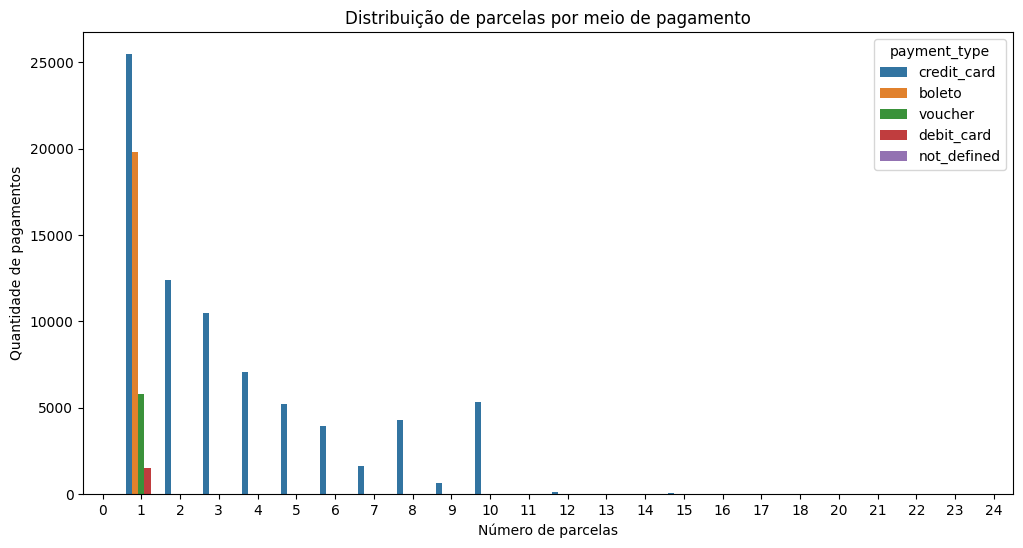

In [10]:
# distribuição de parcelas

plt.figure(figsize=(12,6))

sns.countplot(
    data=df_payments,
    x='payment_installments',
    hue='payment_type'
)

plt.title('Distribuição de parcelas por meio de pagamento')
plt.xlabel('Número de parcelas')
plt.ylabel('Quantidade de pagamentos')

plt.show()

In [11]:
# bases

df_orders = pd.read_csv('/content/olist_orders_dataset.csv')
df_customers = pd.read_csv('/content/olist_customers_dataset.csv')

In [12]:
# Relacionar clientes com pedidos
df_rfm = df_orders.merge(
    df_customers[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='left'
)

# Relacionar pedidos com pagamentos
df_rfm = df_rfm.merge(
    df_payments[['order_id', 'payment_value']],
    on='order_id',
    how='left'
)

df_rfm.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,payment_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,18.12
1,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,2.00
2,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,18.59
3,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231,141.46
4,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8,179.12


In [13]:
# Somar pagamentos por pedido
pagamentos_pedido = df_payments.groupby('order_id').agg(
    valor_pedido=('payment_value', 'sum')
).reset_index()

# Relacionar clientes e pedidos
df_rfm = df_orders.merge(
    df_customers[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='left'
)

# Relacionar valores pagos
df_rfm = df_rfm.merge(
    pagamentos_pedido,
    on='order_id',
    how='left'
)

df_rfm.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,valor_pedido
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,7c142cf63193a1473d2e66489a9ae977,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,72632f0f9dd73dfee390c9b22eb56dd6,28.62


In [14]:
# Converter coluna para datetime
df_rfm['order_purchase_timestamp'] = pd.to_datetime(
    df_rfm['order_purchase_timestamp'],
    errors='coerce'
)

# Remover registros sem data ou identificação do cliente
df_rfm = df_rfm.dropna(
    subset=['customer_unique_id', 'order_purchase_timestamp']
)

In [15]:
# Definir data de referência
data_referencia = df_rfm['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

# Calcular RFM
rfm = df_rfm.groupby('customer_unique_id').agg(
    Recencia=('order_purchase_timestamp',
              lambda x: (data_referencia - x.max()).days),

    Frequencia=('order_id', 'nunique'),

    Monetizacao=('valor_pedido', 'sum')
).reset_index()

rfm.head()

,customer_unique_id,Recencia,Frequencia,Monetizacao
0,0000366f3b9a7992bf8c76cfdf3221e2,161,1,141.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,164,1,27.19
2,0000f46a3911fa3c0805444483337064,586,1,86.22
3,0000f6ccb0745a6a4b88665a16c9f078,370,1,43.62
4,0004aac84e0df4da2b147fca70cf8255,337,1,196.89


In [16]:
# Criar pontuação RFM
rfm['R_score'] = pd.qcut(
    rfm['Recencia'].rank(method='first'),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm['F_score'] = pd.qcut(
    rfm['Frequencia'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm['M_score'] = pd.qcut(
    rfm['Monetizacao'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

In [17]:
rfm['RFM_score'] = (
    rfm['R_score'].astype(str) +
    rfm['F_score'].astype(str) +
    rfm['M_score'].astype(str)
)

rfm['RFM_total'] = (
    rfm['R_score'] +
    rfm['F_score'] +
    rfm['M_score']
)

rfm.head()

,customer_unique_id,Recencia,Frequencia,Monetizacao,R_score,F_score,M_score,RFM_score,RFM_total
0,0000366f3b9a7992bf8c76cfdf3221e2,161,1,141.90,4,1,4,414,9
1,0000b849f77a49e4a4ce2b2a4ca5be3f,164,1,27.19,4,1,1,411,6
2,0000f46a3911fa3c0805444483337064,586,1,86.22,1,1,2,112,4
3,0000f6ccb0745a6a4b88665a16c9f078,370,1,43.62,2,1,1,211,4
4,0004aac84e0df4da2b147fca70cf8255,337,1,196.89,2,1,4,214,7


In [18]:
import numpy as np

condicoes = [
    (rfm['R_score'] >= 4) &
    (rfm['F_score'] >= 4) &
    (rfm['M_score'] >= 4),

    (rfm['R_score'] >= 3) &
    (rfm['F_score'] >= 4),

    (rfm['R_score'] >= 4) &
    (rfm['F_score'] <= 2),

    (rfm['R_score'] <= 2) &
    (rfm['F_score'] >= 3),

    (rfm['R_score'] <= 2) &
    (rfm['F_score'] <= 2)
]

segmentos = [
    'Clientes VIP',
    'Clientes Fidelizados',
    'Clientes Novos',
    'Clientes em Risco',
    'Clientes Perdidos'
]

rfm['Segmento'] = np.select(
    condicoes,
    segmentos,
    default='Clientes Regulares'
)

rfm.head()

,customer_unique_id,Recencia,Frequencia,Monetizacao,R_score,F_score,M_score,RFM_score,RFM_total,Segmento
0,0000366f3b9a7992bf8c76cfdf3221e2,161,1,141.90,4,1,4,414,9,Clientes Novos
1,0000b849f77a49e4a4ce2b2a4ca5be3f,164,1,27.19,4,1,1,411,6,Clientes Novos
2,0000f46a3911fa3c0805444483337064,586,1,86.22,1,1,2,112,4,Clientes Perdidos
3,0000f6ccb0745a6a4b88665a16c9f078,370,1,43.62,2,1,1,211,4,Clientes Perdidos
4,0004aac84e0df4da2b147fca70cf8255,337,1,196.89,2,1,4,214,7,Clientes Perdidos


In [19]:
analise_segmentos = rfm.groupby('Segmento').agg(
    Quantidade_clientes=('customer_unique_id', 'count'),
    Recencia_media=('Recencia', 'mean'),
    Frequencia_media=('Frequencia', 'mean'),
    Monetizacao_media=('Monetizacao', 'mean'),
    Faturamento_total=('Monetizacao', 'sum')
).reset_index()

analise_segmentos.sort_values(
    by='Quantidade_clientes',
    ascending=False
)

,Segmento,Quantidade_clientes,Recencia_media,Frequencia_media,Monetizacao_media,Faturamento_total
5,Clientes em Risco,22975,445.693232,1.049576,168.812254,3878461.53
3,Clientes Regulares,19124,218.462822,1.000000,158.108371,3023664.49
0,Clientes Fidelizados,16465,201.356514,1.057212,116.081800,1911286.84
2,Clientes Perdidos,15463,446.735627,1.000000,164.232723,2539530.60
1,Clientes Novos,15389,140.759634,1.000000,164.624831,2533411.52
4,Clientes VIP,6680,140.614072,1.189222,317.742087,2122517.14


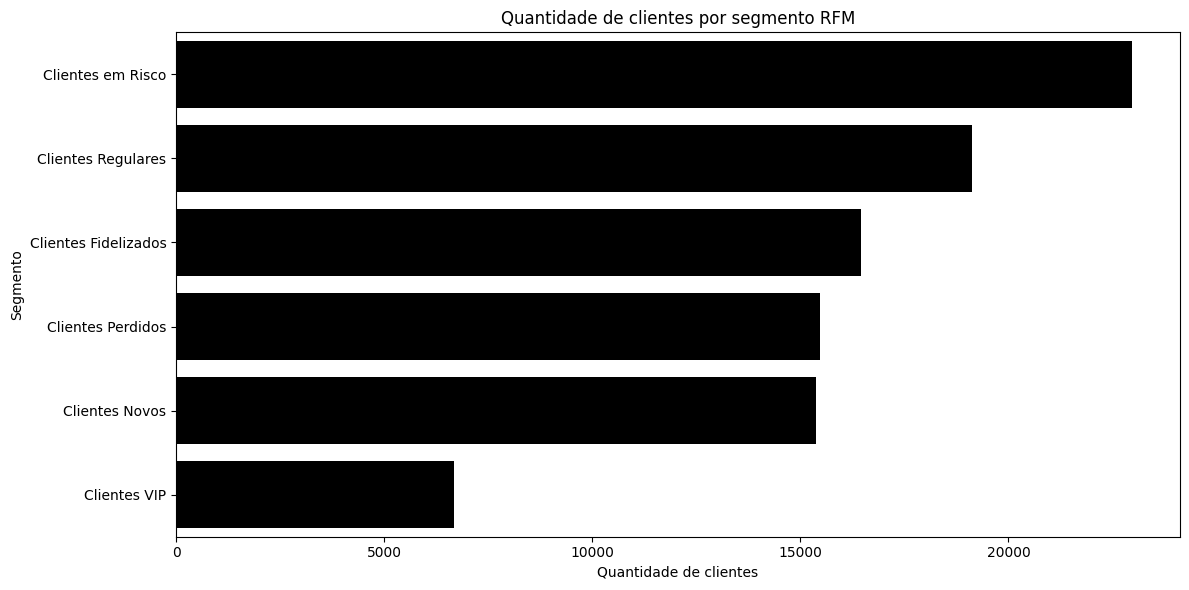

In [39]:
# visualização gráfico por qtde de clientes

# Visualização gráfico por quantidade de clientes

plt.figure(figsize=(12,6), facecolor='none')

ax = sns.countplot(
    data=rfm,
    y='Segmento',
    hue='Segmento',
    order=rfm['Segmento'].value_counts().index,
    legend=False,
    palette=['black'] * rfm['Segmento'].nunique()
)

# Fundo transparente
ax.set_facecolor('none')
plt.gcf().patch.set_alpha(0)
ax.patch.set_alpha(0)

plt.title('Quantidade de clientes por segmento RFM')
plt.xlabel('Quantidade de clientes')
plt.ylabel('Segmento')

plt.tight_layout()

# Salvar com fundo transparente
plt.savefig('clientes_segmento_rfm.png', transparent=True, dpi=300, bbox_inches='tight')

plt.show()

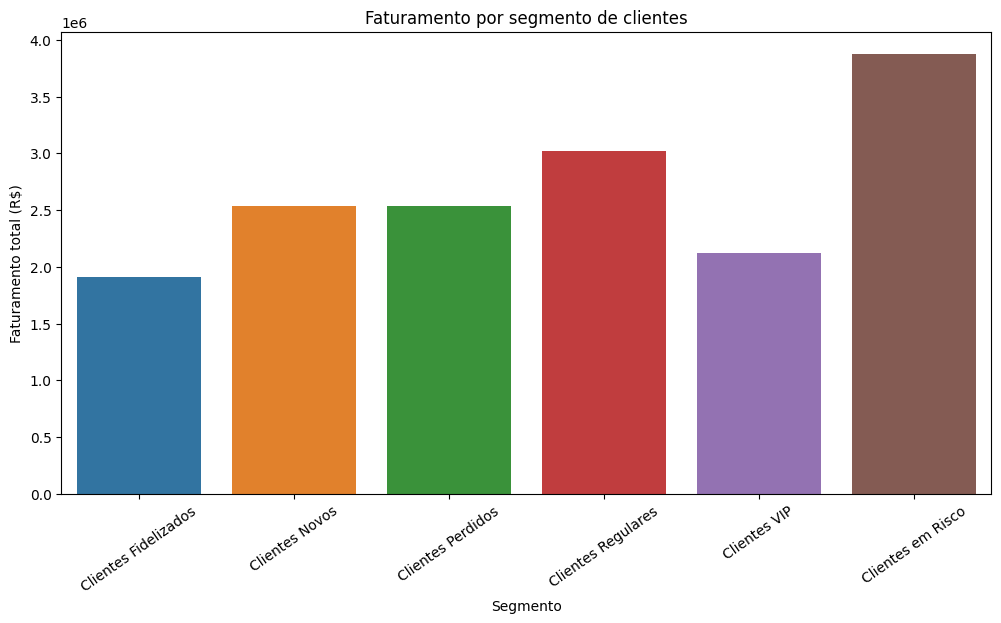

In [21]:
# visualização gráfico faturamento por segmento

plt.figure(figsize=(12,6))

sns.barplot(
    data=analise_segmentos,
    x='Segmento',
    y='Faturamento_total',
    hue='Segmento',
    legend=False
)

plt.title('Faturamento por segmento de clientes')
plt.xlabel('Segmento')
plt.ylabel('Faturamento total (R$)')
plt.xticks(rotation=35)

plt.show()

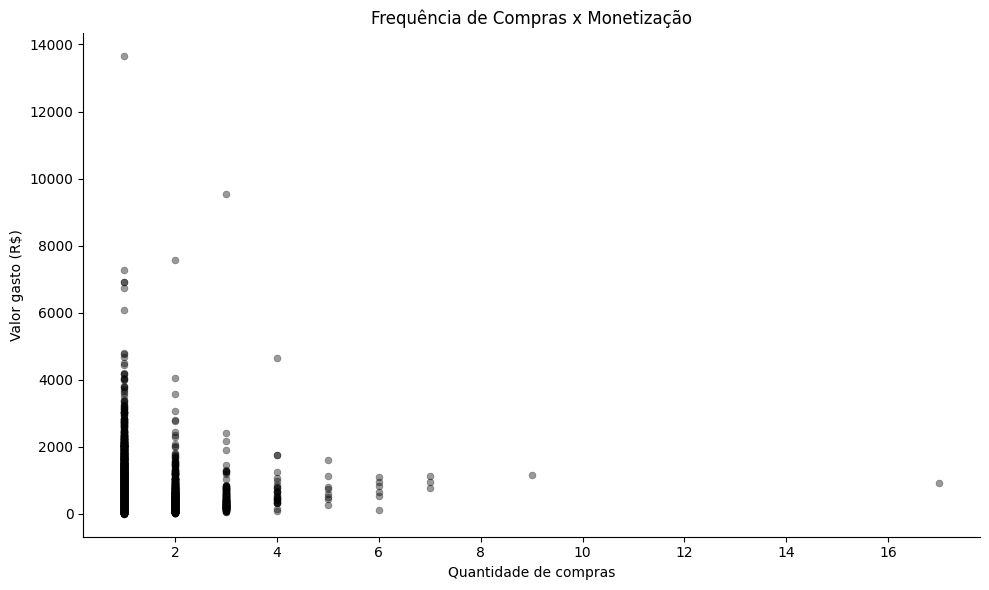

In [43]:
# Quantidade de clientes por segmento
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x='Frequencia',
    y='Monetizacao',
    color='black',
    alpha=0.4,
    s=25,
    edgecolor=None,
    ax=ax
)

# Título e eixos
ax.set_title('Frequência de Compras x Monetização')
ax.set_xlabel('Quantidade de compras')
ax.set_ylabel('Valor gasto (R$)')

# Remover bordas e grade
sns.despine(ax=ax)
ax.grid(False)

# Fundo transparente
fig.patch.set_alpha(0)
ax.patch.set_alpha(0)

plt.tight_layout()

# Salvar com fundo transparente
plt.savefig(
    'frequencia_monetizacao.png',
    transparent=True,
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [23]:
# visualização gráfico 10 melhores clientes

top_clientes = rfm.sort_values(
    by='Monetizacao',
    ascending=False
).head(10)

top_clientes[
    ['customer_unique_id',
     'Recencia',
     'Frequencia',
     'Monetizacao',
     'Segmento']
]

,customer_unique_id,Recencia,Frequencia,Monetizacao,Segmento
3826,0a0a92112bd4c708ca5fde585afaa872,384,1,13664.08,Clientes Perdidos
26456,46450c74a0d8c5ca9395da1daac6c120,61,3,9553.02,Clientes VIP
81962,da122df9eeddfedc1dc1f5349a1a690c,565,2,7571.63,Clientes em Risco
44447,763c8b1c9c68a0229c42c9fc6f662b93,95,1,7274.88,Clientes Regulares
82808,dc4802a71eae9be1dd28f5d788ceb526,612,1,6929.31,Clientes em Risco
26205,459bef486812aa25204be022145caa62,84,1,6922.21,Clientes Novos
95806,ff4159b92c40ebe40454e3e6a7c35ed6,511,1,6726.66,Clientes em Risco
24121,4007669dec559734d6f53e029e360987,328,1,6081.54,Clientes Perdidos
35070,5d0a2980b292d049061542014e8960bf,98,1,4809.44,Clientes Novos
89688,eebb5dda148d3893cdaf5b5ca3040ccb,547,1,4764.34,Clientes em Risco


In [24]:
# Relacionar pedidos com clientes
df_retencao = df_orders.merge(
    df_customers[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='left'
)

# Converter data de compra
df_retencao['order_purchase_timestamp'] = pd.to_datetime(
    df_retencao['order_purchase_timestamp'],
    errors='coerce'
)

# Remover registros sem informações necessárias
df_retencao = df_retencao.dropna(
    subset=['customer_unique_id', 'order_purchase_timestamp']
)

# Considerar somente pedidos válidos e entregues
df_retencao = df_retencao[
    df_retencao['order_status'] == 'delivered'
].copy()

df_retencao.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,7c142cf63193a1473d2e66489a9ae977
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,72632f0f9dd73dfee390c9b22eb56dd6


In [25]:
# Quantidade de pedidos por cliente
compras_cliente = df_retencao.groupby(
    'customer_unique_id'
).agg(
    quantidade_compras=('order_id', 'nunique')
).reset_index()

# Classificar clientes
compras_cliente['Tipo_cliente'] = np.where(
    compras_cliente['quantidade_compras'] > 1,
    'Clientes recorrentes',
    'Clientes de compra única'
)

compras_cliente.head()

,customer_unique_id,quantidade_compras,Tipo_cliente
0,0000366f3b9a7992bf8c76cfdf3221e2,1,Clientes de compra única
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,Clientes de compra única
2,0000f46a3911fa3c0805444483337064,1,Clientes de compra única
3,0000f6ccb0745a6a4b88665a16c9f078,1,Clientes de compra única
4,0004aac84e0df4da2b147fca70cf8255,1,Clientes de compra única


In [26]:
recompra = compras_cliente['Tipo_cliente'].value_counts().reset_index()

recompra.columns = ['Tipo de cliente', 'Quantidade']

recompra['Percentual'] = (
    recompra['Quantidade'] / recompra['Quantidade'].sum()
) * 100

recompra

,Tipo de cliente,Quantidade,Percentual
0,Clientes de compra única,90557,96.999722
1,Clientes recorrentes,2801,3.000278


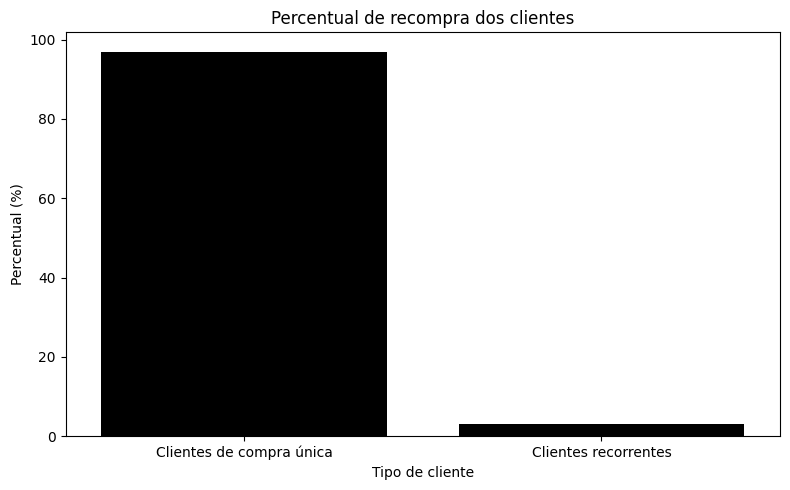

In [45]:
# visualização gráfico recompra

plt.figure(figsize=(8,5), facecolor='none')

ax = sns.barplot(
    data=recompra,
    x='Tipo de cliente',
    y='Percentual',
    hue='Tipo de cliente',
    legend=False,
    palette=['black'] * recompra['Tipo de cliente'].nunique()
)

# Fundo transparente
ax.set_facecolor('none')
plt.gcf().patch.set_alpha(0)
ax.patch.set_alpha(0)

plt.title('Percentual de recompra dos clientes')
plt.xlabel('Tipo de cliente')
plt.ylabel('Percentual (%)')

plt.tight_layout()

# Salvar com fundo transparente
plt.savefig(
    'percentual_recompra.png',
    transparent=True,
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [28]:
# Ordenar compras por cliente e data
df_retencao = df_retencao.sort_values(
    ['customer_unique_id', 'order_purchase_timestamp']
)

# Criar ranking de compras por cliente
df_retencao['numero_compra'] = df_retencao.groupby(
    'customer_unique_id'
).cumcount() + 1

# Selecionar primeira e segunda compra
primeira_compra = df_retencao[
    df_retencao['numero_compra'] == 1
][['customer_unique_id', 'order_purchase_timestamp']]

segunda_compra = df_retencao[
    df_retencao['numero_compra'] == 2
][['customer_unique_id', 'order_purchase_timestamp']]

# Renomear colunas
primeira_compra = primeira_compra.rename(
    columns={'order_purchase_timestamp': 'primeira_compra'}
)

segunda_compra = segunda_compra.rename(
    columns={'order_purchase_timestamp': 'segunda_compra'}
)

# Relacionar as compras
tempo_recompra = primeira_compra.merge(
    segunda_compra,
    on='customer_unique_id',
    how='inner'
)

# Calcular dias entre compras
tempo_recompra['dias_entre_compras'] = (
    tempo_recompra['segunda_compra'] -
    tempo_recompra['primeira_compra']
).dt.days

tempo_recompra.head()

,customer_unique_id,primeira_compra,segunda_compra,dias_entre_compras
0,004288347e5e88a27ded2bb23747066c,2017-07-27 14:13:03,2018-01-14 07:36:54,170
1,00a39521eb40f7012db50455bf083460,2018-05-23 20:14:21,2018-06-03 10:12:57,10
2,00cc12a6d8b578b8ebd21ea4e2ae8b27,2017-03-21 19:25:22,2017-03-21 19:25:23,0
3,011575986092c30523ecb71ff10cb473,2018-02-17 15:54:49,2018-04-18 21:58:08,60
4,011b4adcd54683b480c4d841250a987f,2017-08-22 12:51:29,2018-02-15 11:40:57,176


In [29]:
# média e mediana

tempo_recompra['dias_entre_compras'].agg(
    ['mean', 'median', 'min', 'max']
)

,dias_entre_compras
mean,80.844698
median,28.000000
min,0.000000
max,608.000000


In [30]:
# análise de cohort

# Criar coluna com mês da compra
df_retencao['mes_compra'] = (
    df_retencao['order_purchase_timestamp'].dt.to_period('M')
)

# Identificar o primeiro mês de compra de cada cliente
df_retencao['cohort'] = df_retencao.groupby(
    'customer_unique_id'
)['mes_compra'].transform('min')

df_retencao.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,numero_compra,mes_compra,cohort
52798,e22acc9c116caa3f2b7121bbb380d08e,fadbb3709178fc513abc1b2670aa1ad2,delivered,2018-05-10 10:56:27,2018-05-10 11:11:18,2018-05-12 08:18:00,2018-05-16 20:48:37,2018-05-21 00:00:00,0000366f3b9a7992bf8c76cfdf3221e2,1,2018-05,2018-05
73889,3594e05a005ac4d06a72673270ef9ec9,4cb282e167ae9234755102258dd52ee8,delivered,2018-05-07 11:11:27,2018-05-07 18:25:44,2018-05-09 12:18:00,2018-05-10 18:02:42,2018-05-15 00:00:00,0000b849f77a49e4a4ce2b2a4ca5be3f,1,2018-05,2018-05
26460,b33ec3b699337181488304f362a6b734,9b3932a6253894a02c1df9d19004239f,delivered,2017-03-10 21:05:03,2017-03-10 21:05:03,2017-03-13 12:58:30,2017-04-05 14:38:47,2017-04-07 00:00:00,0000f46a3911fa3c0805444483337064,1,2017-03,2017-03
98493,41272756ecddd9a9ed0180413cc22fb6,914991f0c02ef0843c0e7010c819d642,delivered,2017-10-12 20:29:41,2017-10-12 20:49:17,2017-10-13 20:08:19,2017-11-01 21:23:05,2017-11-13 00:00:00,0000f6ccb0745a6a4b88665a16c9f078,1,2017-10,2017-10
41564,d957021f1127559cd947b62533f484f7,47227568b10f5f58a524a75507e6992c,delivered,2017-11-14 19:45:42,2017-11-14 20:06:52,2017-11-16 19:52:10,2017-11-27 23:08:56,2017-12-05 00:00:00,0004aac84e0df4da2b147fca70cf8255,1,2017-11,2017-11


In [31]:
# Calcular índice do mês de retenção
df_retencao['mes_cohort'] = (
    (df_retencao['mes_compra'].dt.year -
     df_retencao['cohort'].dt.year) * 12
    +
    (df_retencao['mes_compra'].dt.month -
     df_retencao['cohort'].dt.month)
)

df_retencao[
    ['customer_unique_id', 'mes_compra', 'cohort', 'mes_cohort']
].head()

,customer_unique_id,mes_compra,cohort,mes_cohort
52798,0000366f3b9a7992bf8c76cfdf3221e2,2018-05,2018-05,0
73889,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05,2018-05,0
26460,0000f46a3911fa3c0805444483337064,2017-03,2017-03,0
98493,0000f6ccb0745a6a4b88665a16c9f078,2017-10,2017-10,0
41564,0004aac84e0df4da2b147fca70cf8255,2017-11,2017-11,0


In [32]:
# Calcular índice do mês de retenção
df_retencao['mes_cohort'] = (
    (df_retencao['mes_compra'].dt.year -
     df_retencao['cohort'].dt.year) * 12
    +
    (df_retencao['mes_compra'].dt.month -
     df_retencao['cohort'].dt.month)
)

df_retencao[
    ['customer_unique_id', 'mes_compra', 'cohort', 'mes_cohort']
].head()

,customer_unique_id,mes_compra,cohort,mes_cohort
52798,0000366f3b9a7992bf8c76cfdf3221e2,2018-05,2018-05,0
73889,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05,2018-05,0
26460,0000f46a3911fa3c0805444483337064,2017-03,2017-03,0
98493,0000f6ccb0745a6a4b88665a16c9f078,2017-10,2017-10,0
41564,0004aac84e0df4da2b147fca70cf8255,2017-11,2017-11,0


In [33]:
# Contar clientes únicos por cohort e mês
cohort_data = df_retencao.groupby(
    ['cohort', 'mes_cohort']
)['customer_unique_id'].nunique().reset_index()

cohort_data.columns = [
    'cohort',
    'mes_cohort',
    'clientes_ativos'
]

# Criar tabela dinâmica
cohort_pivot = cohort_data.pivot(
    index='cohort',
    columns='mes_cohort',
    values='clientes_ativos'
)

cohort_pivot

mes_cohort,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19,20
cohort,,,,,,,,,,,,,,,,,,,,
2016-09,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-10,262.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,1.0,NaN,1.0,NaN,1.0,NaN,1.0,NaN,1.0,2.0,2.0
2016-12,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01,717.0,2.0,2.0,1.0,3.0,1.0,3.0,1.0,1.0,NaN,3.0,1.0,5.0,3.0,1.0,1.0,2.0,3.0,1.0,NaN
2017-02,1628.0,3.0,5.0,2.0,7.0,2.0,4.0,3.0,2.0,3.0,2.0,5.0,2.0,3.0,2.0,1.0,1.0,3.0,NaN,NaN
2017-03,2503.0,11.0,9.0,10.0,9.0,4.0,4.0,8.0,8.0,2.0,9.0,3.0,5.0,3.0,4.0,6.0,2.0,3.0,NaN,NaN
2017-04,2256.0,14.0,5.0,4.0,6.0,6.0,8.0,7.0,7.0,4.0,6.0,2.0,1.0,1.0,2.0,2.0,3.0,NaN,NaN,NaN
2017-05,3451.0,16.0,16.0,10.0,10.0,11.0,14.0,5.0,9.0,9.0,9.0,12.0,8.0,1.0,6.0,7.0,NaN,NaN,NaN,NaN
2017-06,3037.0,15.0,12.0,13.0,9.0,12.0,11.0,7.0,4.0,6.0,9.0,11.0,5.0,5.0,7.0,NaN,NaN,NaN,NaN,NaN


In [34]:
# Calcular tamanho inicial de cada cohort
cohort_size = cohort_pivot[0]

# Calcular percentual de retenção
retencao = cohort_pivot.divide(
    cohort_size,
    axis=0
) * 100

retencao.round(2)

mes_cohort,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19,20
cohort,,,,,,,,,,,,,,,,,,,,
2016-09,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-10,100.0,NaN,NaN,NaN,NaN,NaN,0.38,NaN,NaN,0.38,NaN,0.38,NaN,0.38,NaN,0.38,NaN,0.38,0.76,0.76
2016-12,100.0,100.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01,100.0,0.28,0.28,0.14,0.42,0.14,0.42,0.14,0.14,NaN,0.42,0.14,0.70,0.42,0.14,0.14,0.28,0.42,0.14,NaN
2017-02,100.0,0.18,0.31,0.12,0.43,0.12,0.25,0.18,0.12,0.18,0.12,0.31,0.12,0.18,0.12,0.06,0.06,0.18,NaN,NaN
2017-03,100.0,0.44,0.36,0.40,0.36,0.16,0.16,0.32,0.32,0.08,0.36,0.12,0.20,0.12,0.16,0.24,0.08,0.12,NaN,NaN
2017-04,100.0,0.62,0.22,0.18,0.27,0.27,0.35,0.31,0.31,0.18,0.27,0.09,0.04,0.04,0.09,0.09,0.13,NaN,NaN,NaN
2017-05,100.0,0.46,0.46,0.29,0.29,0.32,0.41,0.14,0.26,0.26,0.26,0.35,0.23,0.03,0.17,0.20,NaN,NaN,NaN,NaN
2017-06,100.0,0.49,0.40,0.43,0.30,0.40,0.36,0.23,0.13,0.20,0.30,0.36,0.16,0.16,0.23,NaN,NaN,NaN,NaN,NaN


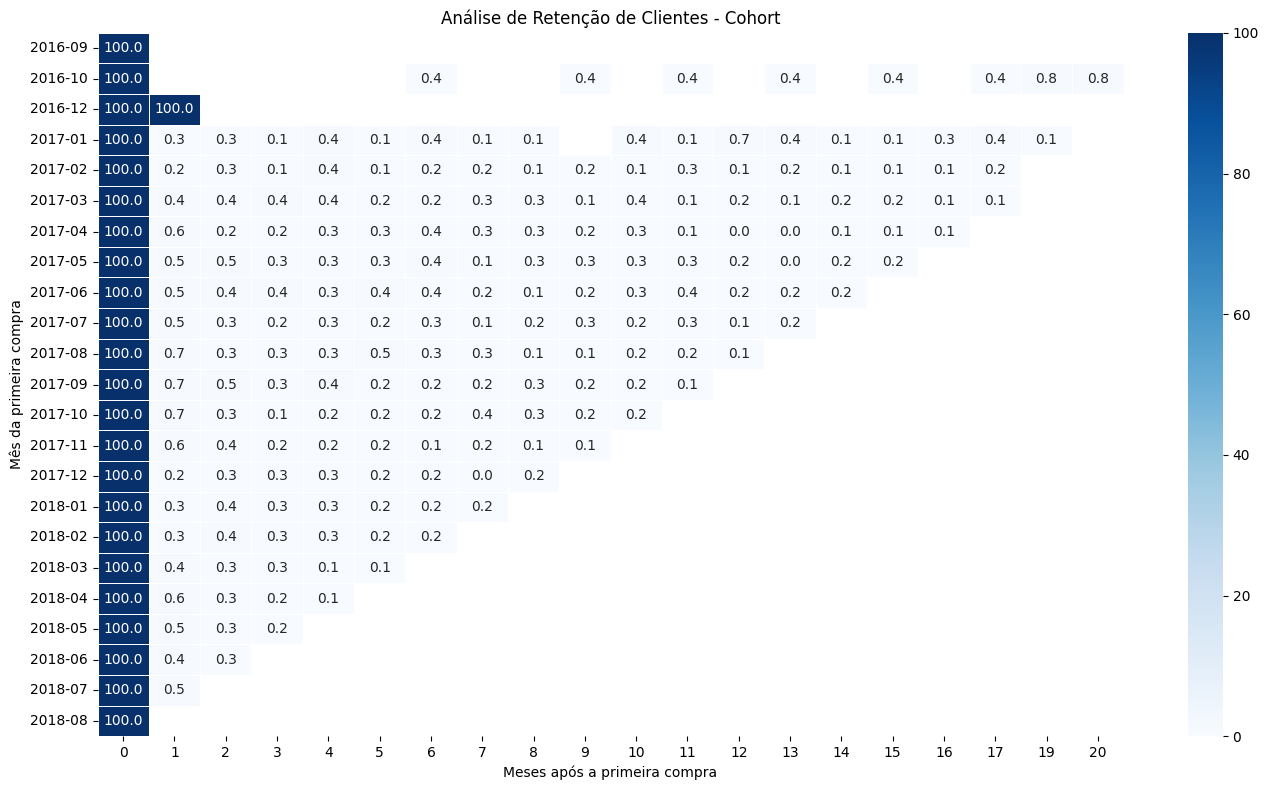

In [51]:
# Visualização gráfico com fundo transparente

fig, ax = plt.subplots(figsize=(14,8))

sns.heatmap(
    retencao,
    annot=True,
    fmt='.1f',
    cmap='Blues',
    linewidths=0.5,
    vmin=0,
    vmax=100,
    ax=ax
)

# Fundo transparente
fig.patch.set_alpha(0)
ax.set_facecolor('none')
ax.patch.set_alpha(0)

plt.title('Análise de Retenção de Clientes - Cohort')
plt.xlabel('Meses após a primeira compra')
plt.ylabel('Mês da primeira compra')

plt.tight_layout()

# Salvar com fundo transparente
plt.savefig(
    'retencao_clientes_cohort.png',
    transparent=True,
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [36]:
# Adicionar estado à base de clientes
df_estado = df_retencao.merge(
    df_customers[['customer_id', 'customer_state']],
    on='customer_id',
    how='left'
)

# Quantidade de pedidos por cliente e estado
recompra_estado = df_estado.groupby(
    ['customer_state', 'customer_unique_id']
).agg(
    compras=('order_id', 'nunique')
).reset_index()

# Classificar recompra
recompra_estado['recorrente'] = (
    recompra_estado['compras'] > 1
)

# Calcular percentual por estado
resultado_estado = recompra_estado.groupby('customer_state').agg(
    total_clientes=('customer_unique_id', 'count'),
    clientes_recorrentes=('recorrente', 'sum')
).reset_index()

resultado_estado['percentual_recompra'] = (
    resultado_estado['clientes_recorrentes'] /
    resultado_estado['total_clientes']
) * 100

resultado_estado.sort_values(
    'percentual_recompra',
    ascending=False
).head(10)

,customer_state,total_clientes,clientes_recorrentes,percentual_recompra
0,AC,76,4,5.263158
20,RO,231,9,3.896104
12,MT,856,28,3.271028
18,RJ,11917,387,3.247462
25,SP,39156,1213,3.097865
8,GO,1895,58,3.060686
22,RS,5168,157,3.037926
7,ES,1928,56,2.904564
17,PR,4769,138,2.893688
10,MG,11001,318,2.890646


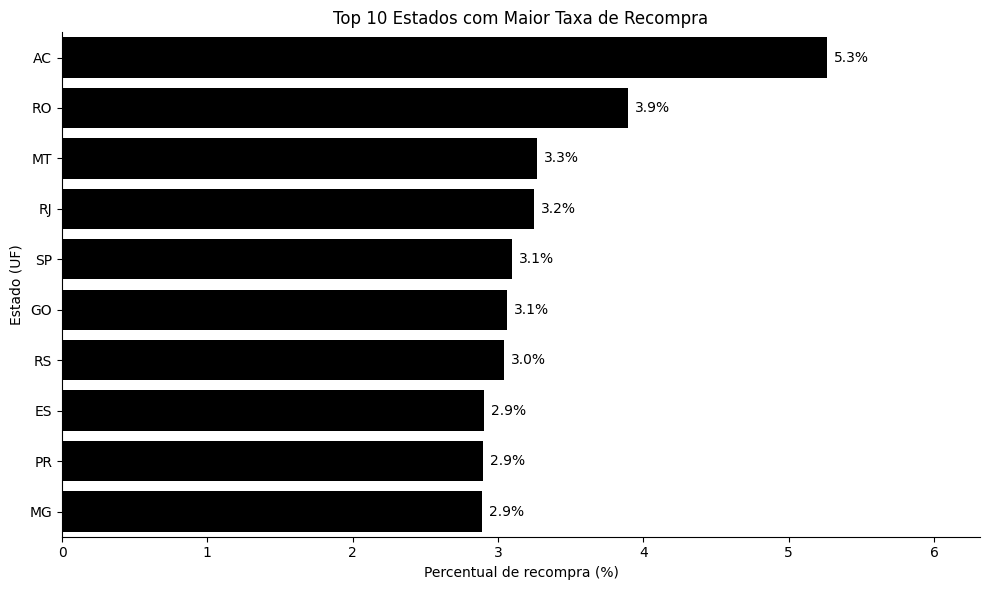

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns

# Selecionar os 10 estados com maior percentual de recompra
top10_estados = resultado_estado.sort_values(
    'percentual_recompra',
    ascending=False
).head(10)

# Criar gráfico
fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=top10_estados,
    x='percentual_recompra',
    y='customer_state',
    color='black',
    ax=ax
)

# Adicionar percentual nas barras
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.1f%%',
        padding=5,
        fontsize=10,
        color='black'
    )

# Título e eixos
ax.set_title('Top 10 Estados com Maior Taxa de Recompra')
ax.set_xlabel('Percentual de recompra (%)')
ax.set_ylabel('Estado (UF)')

# Visual minimalista
sns.despine(ax=ax)
ax.grid(False)

# Ajustar limite para exibir os valores
ax.set_xlim(0, top10_estados['percentual_recompra'].max() * 1.2)

# Fundo transparente
fig.patch.set_alpha(0)
ax.patch.set_alpha(0)

plt.tight_layout()

# Salvar gráfico transparente
plt.savefig(
    'recompra_por_estado.png',
    transparent=True,
    dpi=300,
    bbox_inches='tight'
)

plt.show()